Saving Screenshot 2025-03-18 093351.png to Screenshot 2025-03-18 093351.png


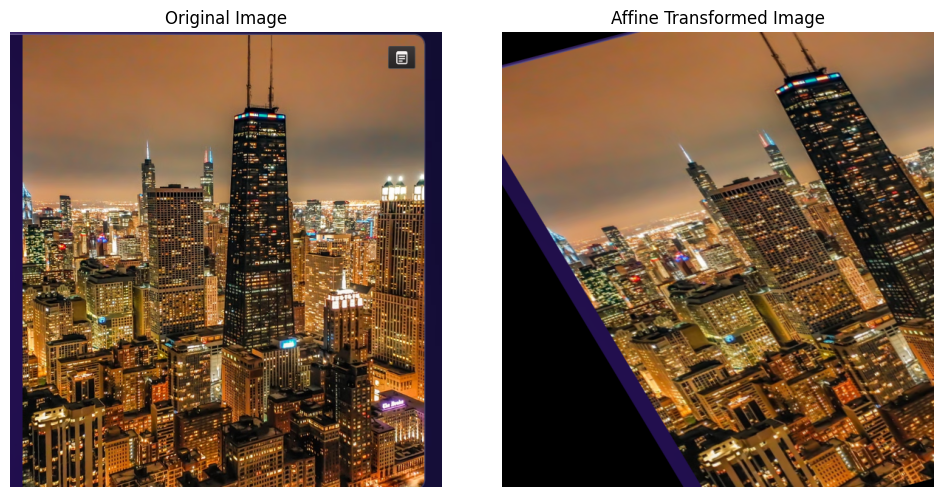

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload an image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read the image
img = cv2.imread(filename)

if img is None:
    print("Error: Image not found!")
else:
    # Get image dimensions
    rows, cols = img.shape[:2]

    # Select three points from the original image
    pts1 = np.float32([
        [50, 50],
        [200, 50],
        [50, 200]
    ])

    # Select corresponding destination points
    pts2 = np.float32([
        [10, 100],
        [200, 50],
        [100, 250]
    ])

    # Calculate affine transformation matrix
    matrix = cv2.getAffineTransform(pts1, pts2)

    # Apply affine transformation
    transformed = cv2.warpAffine(img, matrix, (cols, rows))

    # Convert BGR to RGB for display
    original_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    transformed_rgb = cv2.cvtColor(
        transformed, cv2.COLOR_BGR2RGB
    )

    # Display original and transformed images
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(transformed_rgb)
    plt.title("Affine Transformed Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Save and download the output image
    cv2.imwrite("affine_transformed_image.jpg", transformed)
    files.download("affine_transformed_image.jpg")